In [1]:
from preprocess import normalize
from plotting_and_evaluation import *

In [2]:
data_dir = Path("./data/Tumor_Immune_Evasion_eTRACER/processed_data")
adata = sc.read_h5ad( data_dir / "eTracer_lineage_usable.h5ad")
adata.X = adata.X.astype(np.float64)

adata

AnnData object with n_obs × n_vars = 10755 × 32285
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'RNA_snn_res.0.2', 'seurat_clusters', 'pANN_0.25_0.12_592', 'Doublet_or_Singlet', 'pANN_0.25_0.21_600', 'pANN_0.25_0.19_742', 'time', 'Assignment_0.7', 'RNA_snn_res.0.5', 'pANN_0.25_0.28_666', 'pANN_0.25_0.17_630', 'pANN_0.25_0.29_759', 'pANN_0.25_0.28_612', 'pANN_0.25_0.14_771', 'pANN_0.25_0.07_798', 'RNA_snn_res.0.3', 'harmony_clusters', 'seurat_clusters_rename', 'umapharmony_1', 'umapharmony_2', 'cellName', 'lineageGrp', 'tumor_state', 'color', 'lineageGrp_from_table', 'lineageGrp_final', 'has_lineage', 'replicate', 'stage', 'stage_name', 'time_week', 'n_edit_events', 'lineage_usable', 'lineage_index', 'time_index'
    layers: 'counts'

In [3]:
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=4000, subset=True)
adata = normalize(adata,
                  size_factors=True,
                  normalize_input=True,
                  logtrans_input=True)
adata

AnnData object with n_obs × n_vars = 10755 × 4000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'RNA_snn_res.0.2', 'seurat_clusters', 'pANN_0.25_0.12_592', 'Doublet_or_Singlet', 'pANN_0.25_0.21_600', 'pANN_0.25_0.19_742', 'time', 'Assignment_0.7', 'RNA_snn_res.0.5', 'pANN_0.25_0.28_666', 'pANN_0.25_0.17_630', 'pANN_0.25_0.29_759', 'pANN_0.25_0.28_612', 'pANN_0.25_0.14_771', 'pANN_0.25_0.07_798', 'RNA_snn_res.0.3', 'harmony_clusters', 'seurat_clusters_rename', 'umapharmony_1', 'umapharmony_2', 'cellName', 'lineageGrp', 'tumor_state', 'color', 'lineageGrp_from_table', 'lineageGrp_final', 'has_lineage', 'replicate', 'stage', 'stage_name', 'time_week', 'n_edit_events', 'lineage_usable', 'lineage_index', 'time_index', 'n_counts', 'size_factors'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'
    layers: 'counts'

In [4]:
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcdefaults()

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'savefig.facecolor': 'white',
    'savefig.edgecolor': 'none',
    'savefig.transparent': False,

    'text.color':       'black',
    'axes.labelcolor':  'black',
    'axes.edgecolor':   'black',
    'xtick.color':      'black',
    'ytick.color':      'black',

    'legend.facecolor': 'white',
    'legend.edgecolor': 'black',
    'legend.frameon':   False,
})

In [5]:
output_dir = Path(f"results_all/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results/Figures/adata_time_week.pdf


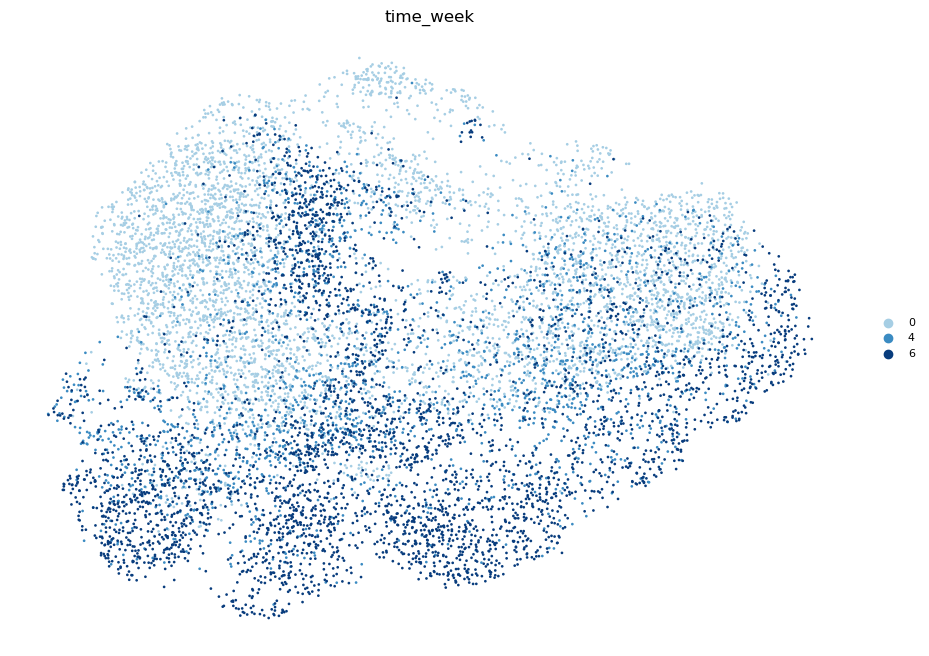

In [6]:
size = 15
time_order = sorted(adata.obs['time_week'].unique())
adata.obs['time_week'] = pd.Categorical(adata.obs['time_week'], categories=time_order, ordered=True)
plot_show_adata(adata, color_feature="time_week",
    size=size,
    output_dir=output_dir,
    use_gradient_for_categories=True,
    gradient_cmap="Blues" )

Top clones:
C5     1077
C10     932
C14     696
C3      584
C7      538
C24     358
C31     276
C26     266
C28     256
C36     254
Name: lineageGrp_final, dtype: int64
already
Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results/Figures/adata_top_clone.pdf


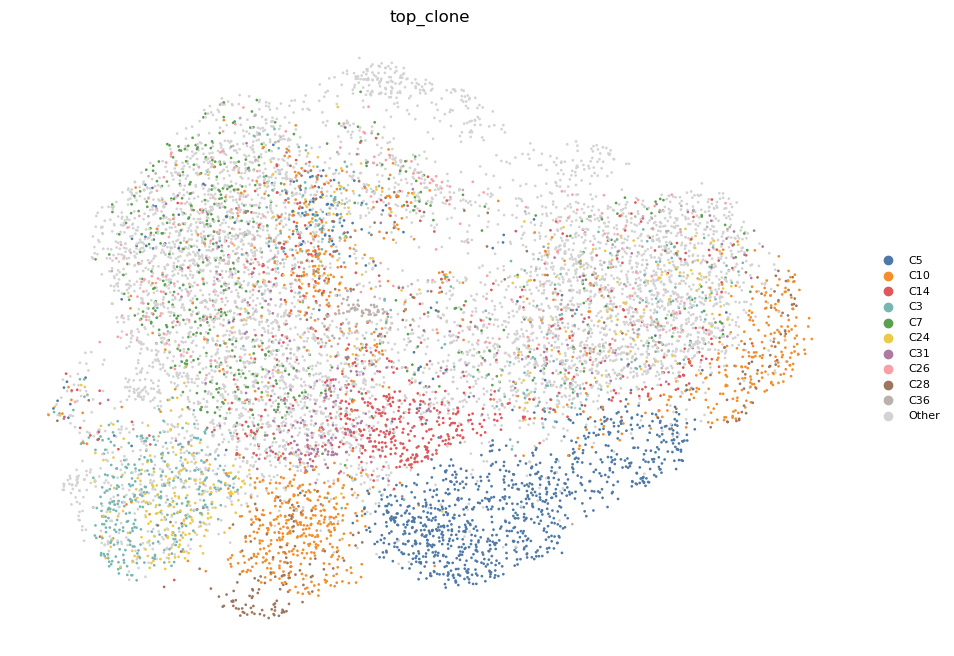

In [7]:
top_n = 10

clone_counts = adata.obs["lineageGrp_final"].value_counts()
top_clones = clone_counts.head(top_n).index.tolist()

print("Top clones:")
print(clone_counts.head(top_n))

adata.obs["top_clone"] = (
    adata.obs["lineageGrp_final"]
    .astype(str)
    .where(
        adata.obs["lineageGrp_final"].isin(top_clones),
        "Other"
    )
)

categories = [str(c) for c in top_clones] + ["Other"]

adata.obs["top_clone"] = pd.Categorical(
    adata.obs["top_clone"],
    categories=categories,
    ordered=True
)

colors = [
    "#4E79A7",
    "#F28E2B",
    "#E15759",
    "#76B7B2",
    "#59A14F",
    "#EDC949",
    "#AF7AA1",
    "#FF9DA7",
    "#9C755F",
    "#BAB0AC",
]

color_map = {
    str(clone): mcolors.to_hex(colors[i])
    for i, clone in enumerate(top_clones)
}
color_map["Other"] = "#D3D3D3"

plot_show_adata(adata, color_feature="top_clone", color_map=color_map, size=size, output_dir=output_dir)

In [8]:
final_latent = np.loadtxt("final_latent.txt", delimiter=",")
gp_latent = np.loadtxt("gp_latent.txt", delimiter=",")
gp_T_latent = np.loadtxt("gp_T_latent.txt", delimiter=",")
gaussian_latent = np.loadtxt("gaussian_latent.txt", delimiter=",")

adata.obsm["DeepTracing_UV"] = final_latent
adata.obsm["DeepTracing_LV"] = gp_latent
adata.obsm["DeepTracing_TV"] = gp_T_latent
adata.obsm["DeepTracing_IV"] = gaussian_latent

scvi_dir = Path("./results_scvi/scvi_latent_eTracer.txt")
scvi_latent = np.loadtxt(scvi_dir, delimiter=",")
adata.obsm["scVI"] = scvi_latent

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results/Figures/adata_embeddings_DeepTracing_UV_top_clone.pdf


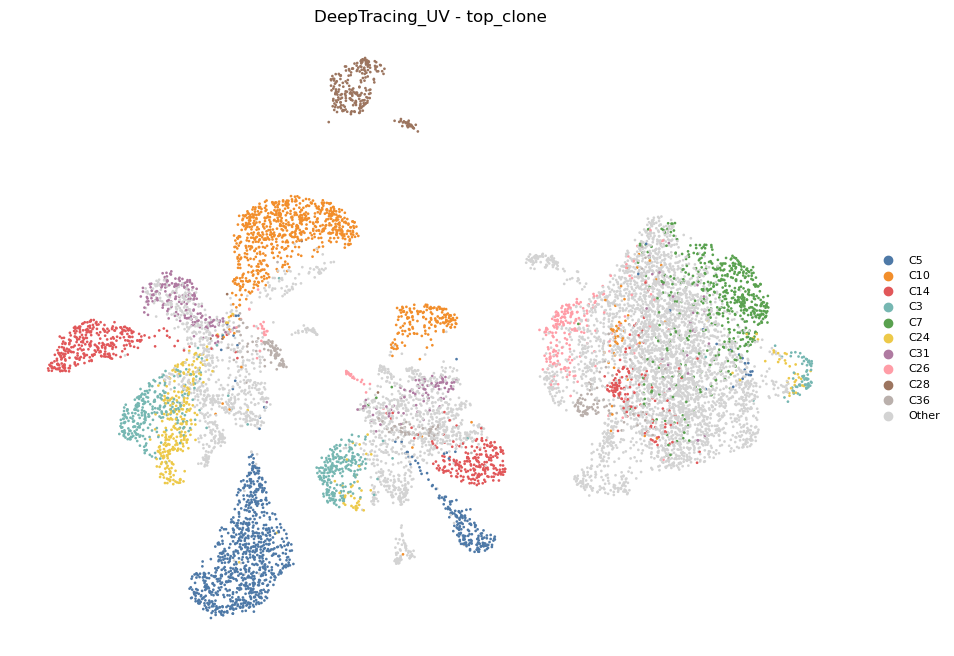

Image saved to: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results/Figures/adata_embeddings_DeepTracing_UV_time_week.pdf


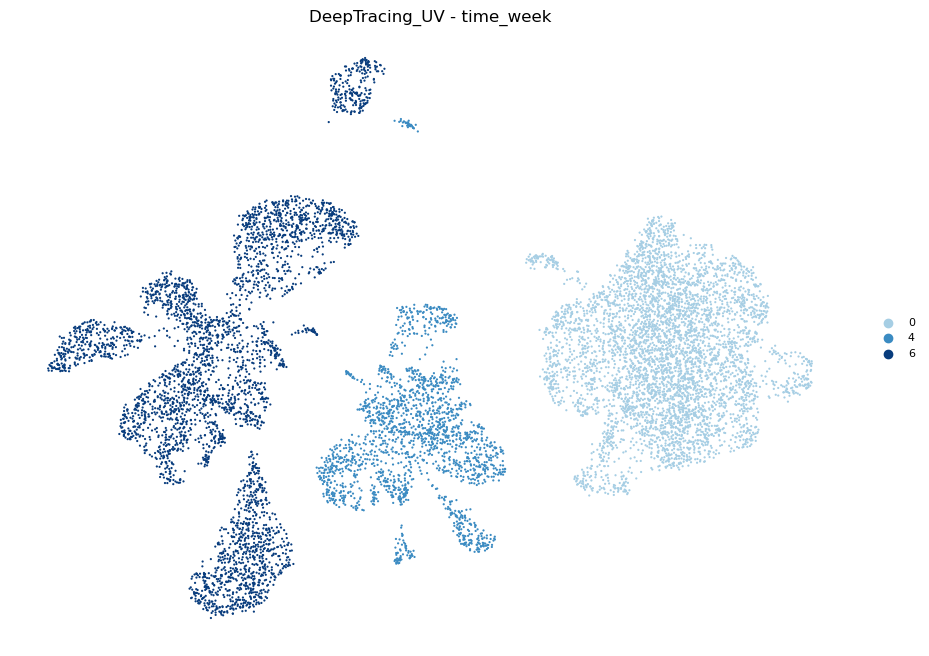

In [9]:
plot_umap_embeddings(adata, rep_keys=["DeepTracing_UV"],  color_keys=["top_clone"], color_map=color_map, size=size, output_dir=output_dir)

plot_umap_embeddings(adata, rep_keys=["DeepTracing_UV"], color_keys = ["time_week"], output_dir=output_dir, use_gradient_for_categories=True,
                     gradient_cmap="Blues" )

Observed times in time_week: [0, 4, 6]
Saved: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results/clone_dynamics/umap_X_pca_top_clone_time_state_arrow.pdf | centers=90 edges=49


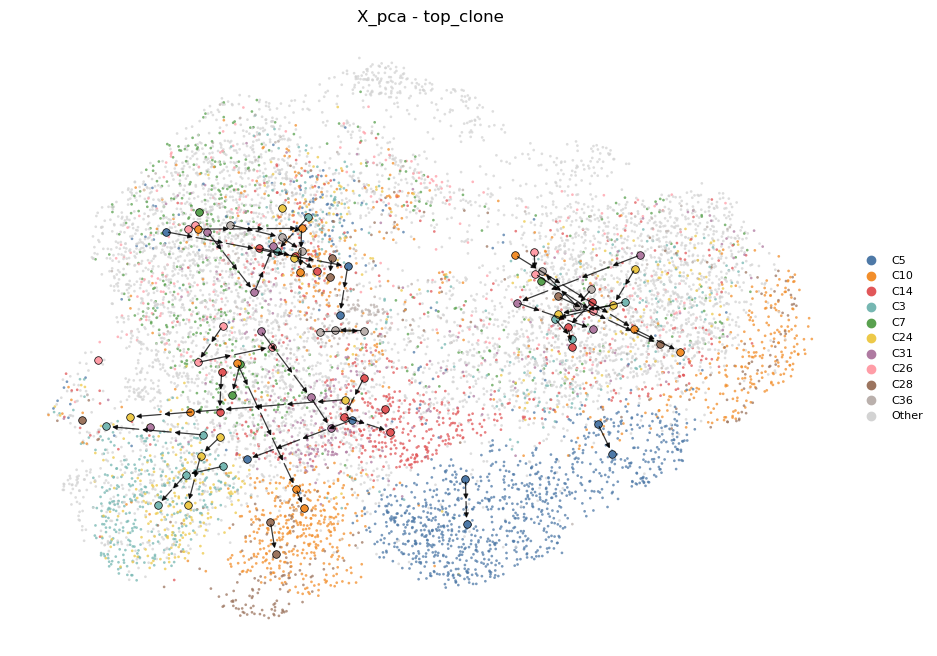

In [10]:
clone_output_dir = Path(f"./results_all/clone_dynamics")
clone_output_dir.mkdir(parents=True, exist_ok=True)

if adata.X.shape[1] > 50:
    sc.tl.pca(adata, n_comps=50, svd_solver='arpack')
    X_pca = adata.obsm['X_pca']
else:
    X_pca = adata.X.copy()

adata.obsm["X_pca"] = X_pca

centers, edges = plot_clone_time_state_umap(
    adata=adata,
    rep_key="X_pca",
    clone_key="top_clone",
    state_key="tumor_state",
    time_key="time_week",
    time_order=(0, 4, 6),
    clones_to_draw=["C5", "C10", "C14", "C3", "C7",
                    "C24", "C31", "C26", "C28", "C36"],
    color_map=color_map,
    size=15,
    center_size=30,
    arrow_lw=0.9,
    arrow_seg_len=0.6,
    arrow_gap_frac=0.1,
    arrow_head_scale=7,
    arrow_shrink_start=2,
    arrow_shrink_end=4,
    min_cells=3,
    output_dir=clone_output_dir,
)

Observed times in time_week: [0, 4, 6]
Saved: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results/clone_dynamics/umap_DeepTracing_UV_top_clone_time_state_arrow.pdf | centers=90 edges=49


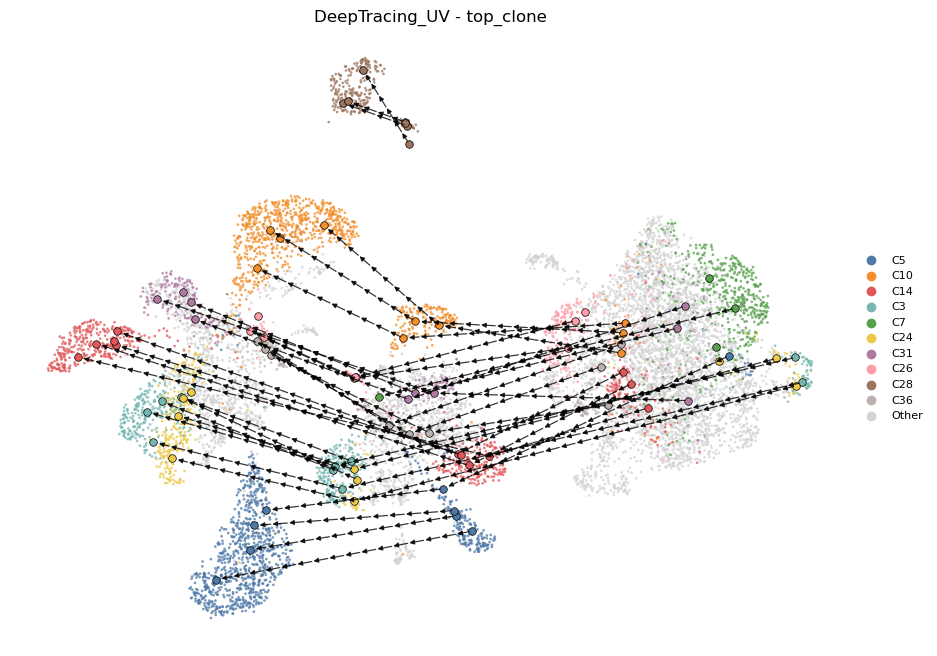

In [11]:
centers, edges = plot_clone_time_state_umap(
    adata=adata,
    rep_key="DeepTracing_UV",
    clone_key="top_clone",
    state_key="tumor_state",
    time_key="time_week",
    time_order=(0, 4, 6),
    clones_to_draw=["C5", "C10", "C14", "C3", "C7",
                    "C24", "C31", "C26", "C28", "C36"],
    color_map=color_map,
    size=15,
    center_size=30,
    arrow_lw=0.9,
    arrow_seg_len=0.6,
    arrow_gap_frac=0.1,
    arrow_head_scale=7,
    arrow_shrink_start=2,
    arrow_shrink_end=4,
    min_cells=3,
    output_dir=clone_output_dir,
)

In [12]:
# Evaluate the representations already loaded and plotted above; no latent files are reloaded.
label_configs = [("Stage", "stage_name"), ("Lineage", "lineageGrp_final")]
embedding_keys = ["X_pca", "scVI", "DeepTracing_UV", "DeepTracing_LV", "DeepTracing_TV", "DeepTracing_IV"]
scib_output_dir = Path("./results_all/scib_results")

full, summary, benchmarkers = evaluate_scib(
    adata=adata, embedding_keys=embedding_keys, label_configs=label_configs,
    output_dir=scib_output_dir, n_jobs=8
)
print("\nSummary scores:\n", summary.round(4))


Evaluating Stage Conservation (obs['stage_name'])...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s, Bio conservation: nmi_ari_cluster_labels_kmeans]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 6/6 [00:16<00:00,  2.67s/it]o conservation: silhouette_label]

           


Evaluating Lineage Conservation (obs['lineageGrp_final'])...
Enabled metric groups: ['Bio conservation']


Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Metrics:   0%|          | 0/5 [00:00<?, ?it/s]
                                                                                          
Embeddings: 100%|██████████| 6/6 [00:40<00:00,  6.78s/it]o conservation: silhouette_label]

                                                                                          


Summary scores:
                 Stage Conservation  Lineage Conservation
Embedding                                               
X_pca                       0.2190                0.2685
scVI                        0.2351                0.3080
DeepTracing_UV              0.6774                0.4281
DeepTracing_LV              0.2366                0.4592
DeepTracing_TV              1.0000                0.1447
DeepTracing_IV              0.1729                0.1649



Conservation scores:
                 Lineage Conservation  Stage Conservation
Embedding                                               
X_pca                         0.2685              0.2190
scVI                          0.3080              0.2351
DeepTracing_UV                0.4281              0.6774
DeepTracing_LV                0.4592              0.2366
DeepTracing_TV                0.1447              1.0000
DeepTracing_IV                0.1649              0.1729


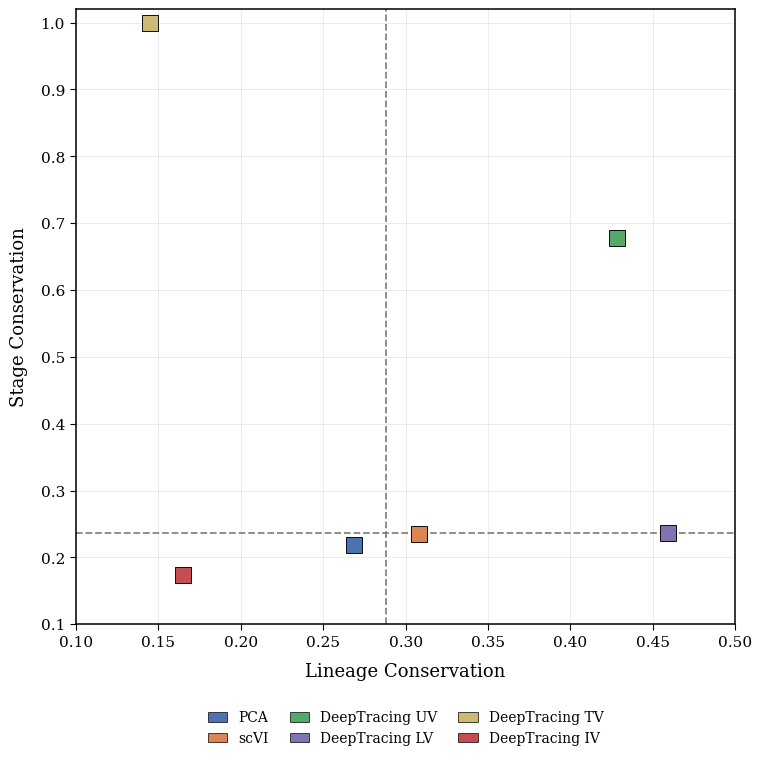

[Lineage Conservation vs Stage Conservation]
  Lineage Conservation median : 0.2882
  Stage Conservation median : 0.2359
  axis limits   : x=(0.1, 0.5), y=(0.1, 1.02)
  saved         : results/scib_results/scatter/Lineage_Conservation_vs_Stage_Conservation_scatter.svg
  saved         : results/scib_results/scatter/Lineage_Conservation_vs_Stage_Conservation_scatter.pdf


In [13]:
# Save the Lineage vs Stage conservation scatter and show it in Jupyter.
plot_conservation_scatter(summary, output_dir=scib_output_dir / "scatter")

Computing raw temporal differential expression
Loaded 10755 cells x 4000 genes (original unnormalized counts).
Time counts: {0: 4915, 4: 1976, 6: 3864}
Lineage count: 80
Lineage     C1                     0->4 n=14/81 tested=2189 significant=101
Lineage     C1                     4->6 n=81/12 tested=2148 significant=105
Lineage     C10                    0->4 n=45/170 tested=2502 significant=335
Lineage     C10                    4->6 n=170/717 tested=2530 significant=34
Lineage     C12                    0->4 n=68/35 tested=2175 significant=440
Lineage     C12                    4->6 n=35/25 tested=1998 significant=51
Lineage     C120                   4->6 n=54/12 tested=2046 significant=12
Lineage     C13                    4->6 n=38/13 tested=1800 significant=14
Lineage     C14                    0->4 n=130/222 tested=2525 significant=230
Lineage     C14                    4->6 n=222/344 tested=2485 significant=105
Lineage     C161                   0->4 n=18/19 tested=1603 signifi

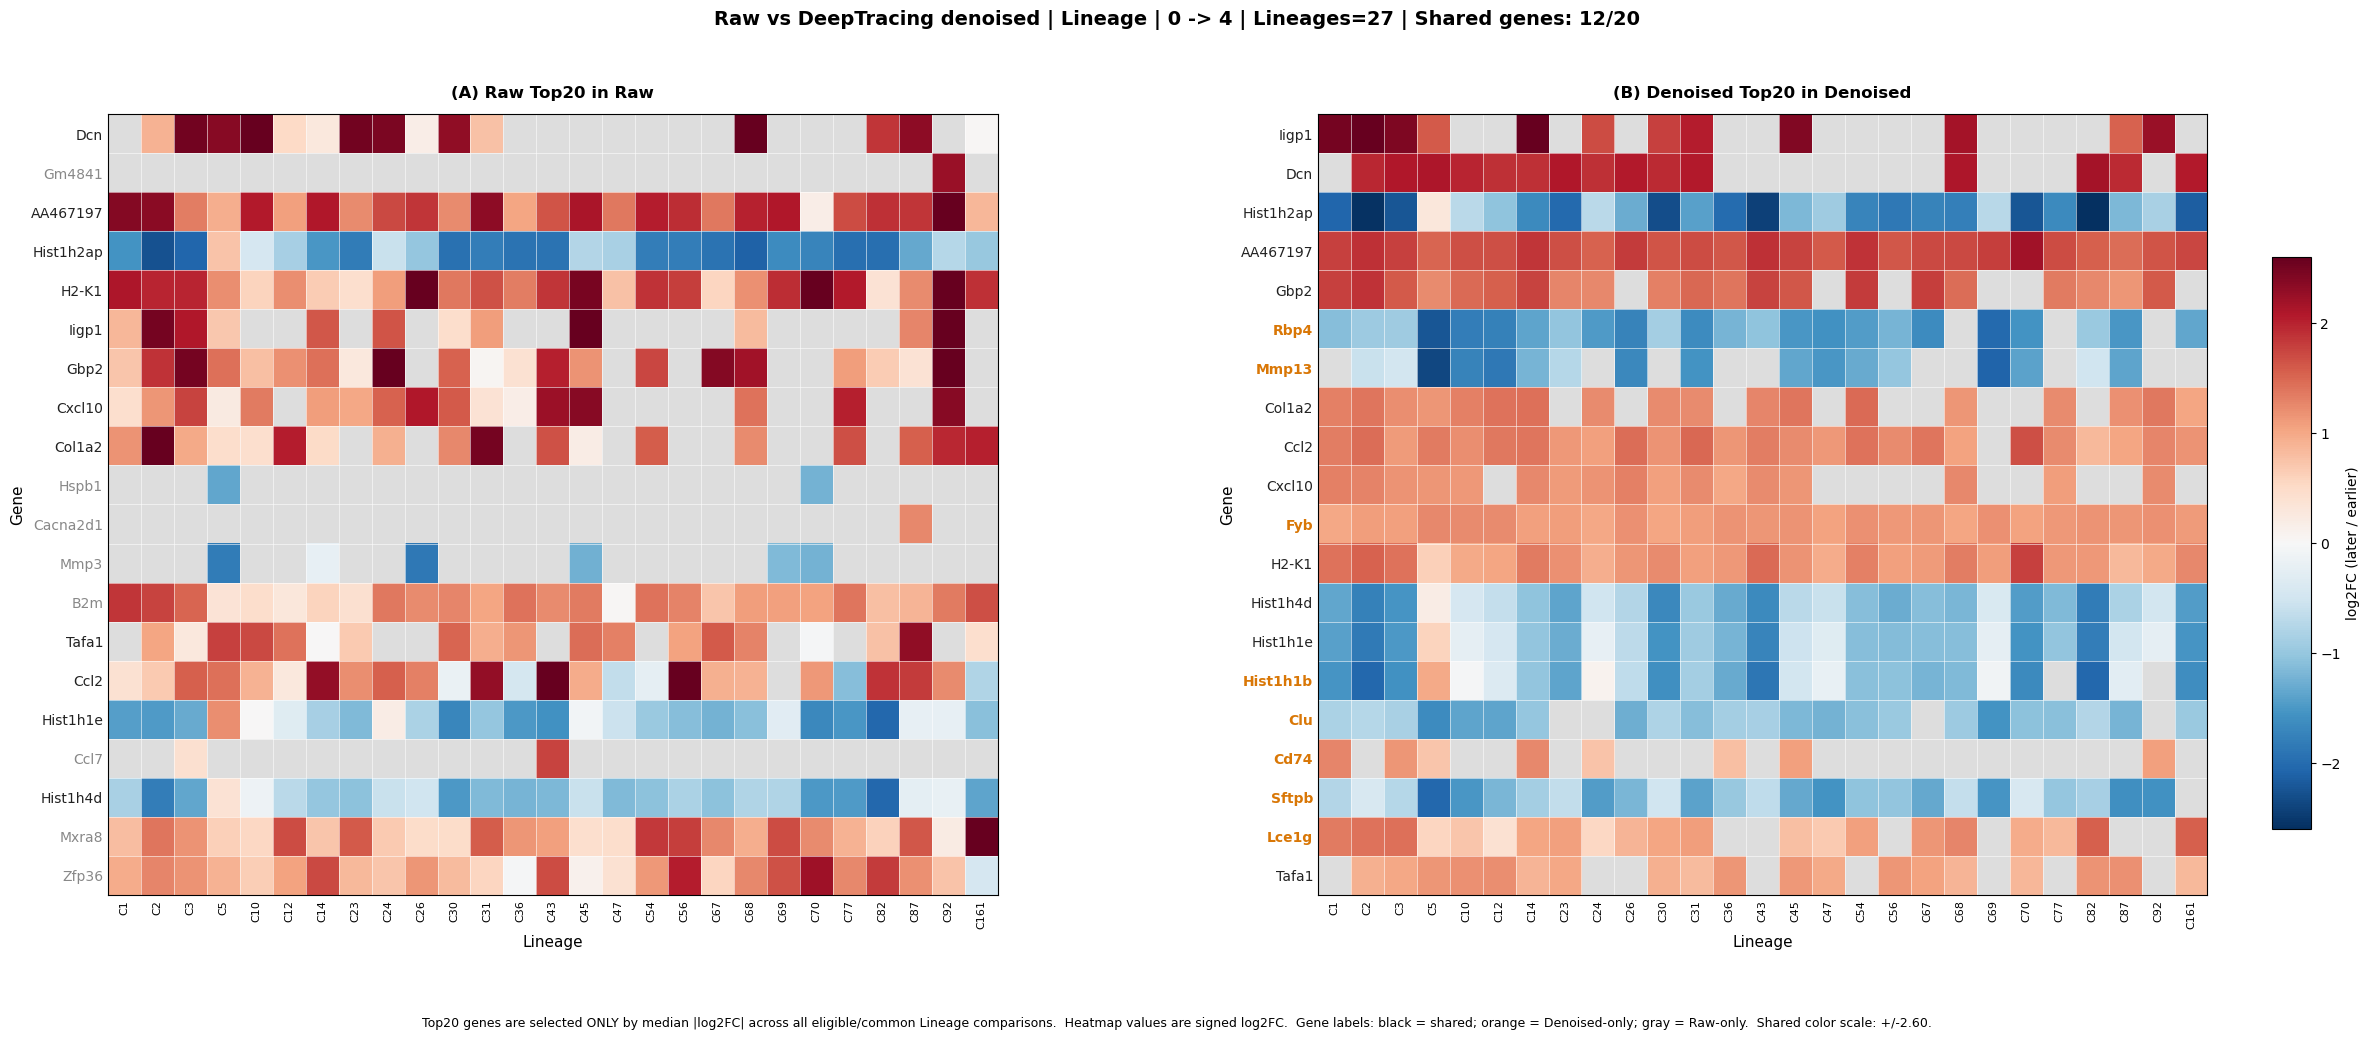

[SAVED] Lineage__0_to_4__raw_vs_denoised_top20__median_abs_heatmap | clones=27 shared genes=4000 overlap=12/20 | scale +/-2.600
  Shared genes: AA467197, Ccl2, Col1a2, Cxcl10, Dcn, Gbp2, H2-K1, Hist1h1e, Hist1h2ap, Hist1h4d, Iigp1, Tafa1
  Denoised-only: Cd74, Clu, Fyb, Hist1h1b, Lce1g, Mmp13, Rbp4, Sftpb
  Raw-only: B2m, Cacna2d1, Ccl7, Gm4841, Hspb1, Mmp3, Mxra8, Zfp36


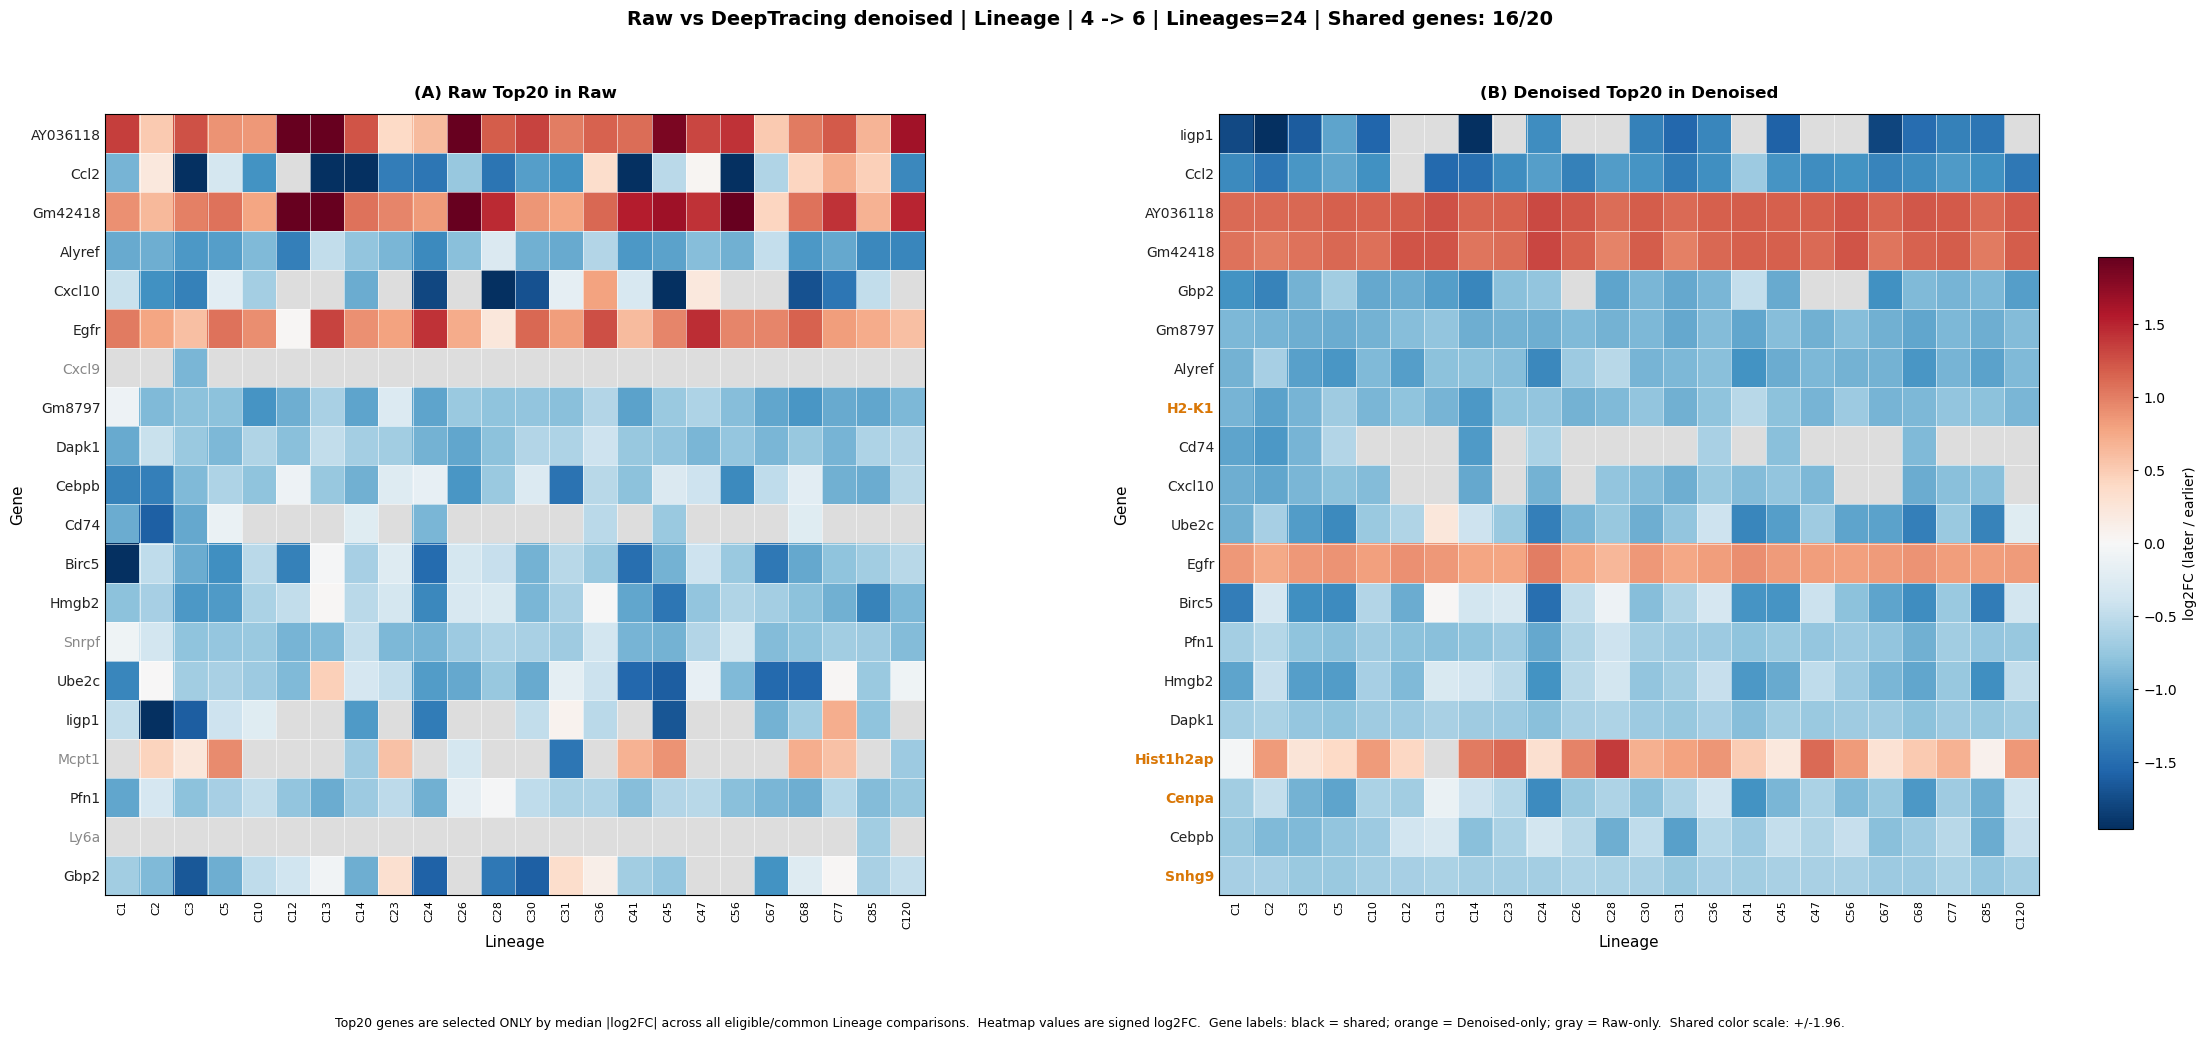

[SAVED] Lineage__4_to_6__raw_vs_denoised_top20__median_abs_heatmap | clones=24 shared genes=4000 overlap=16/20 | scale +/-1.956
  Shared genes: Alyref, AY036118, Birc5, Ccl2, Cd74, Cebpb, Cxcl10, Dapk1, Egfr, Gbp2, Gm8797, Gm42418, Hmgb2, Iigp1, Pfn1, Ube2c
  Denoised-only: Cenpa, H2-K1, Hist1h2ap, Snhg9
  Raw-only: Cxcl9, Ly6a, Mcpt1, Snrpf
Done: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results_gene_analyse/raw_vs_denoised_top20_median_abs_heatmap
Drawing matched Top20 bar charts
Restricting Raw and Denoised to the same 4000 training genes and selected common groups.


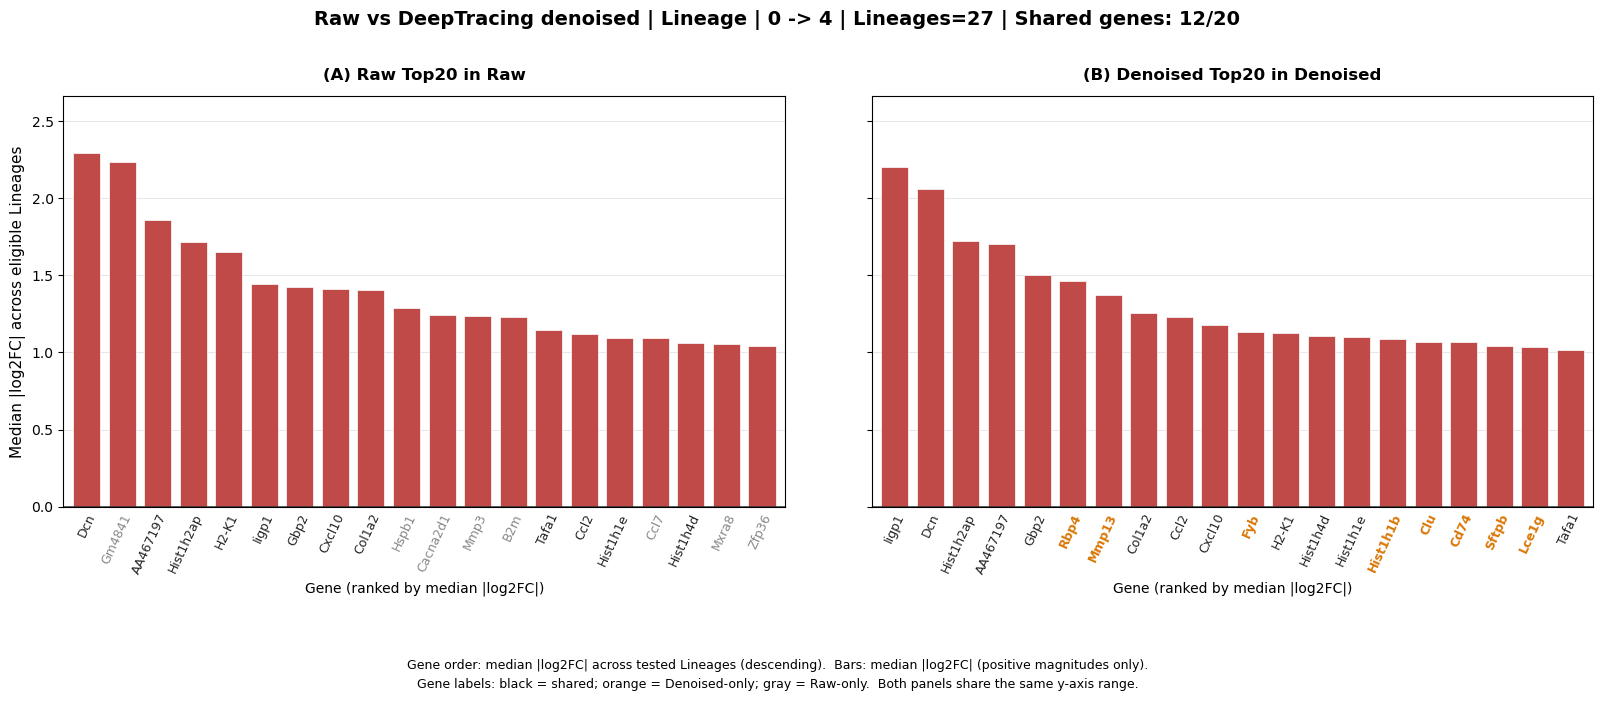

[SAVED] Lineage__0_to_4__raw_vs_denoised_top20__absolute_vertical_bars | groups=27 shared genes=4000 overlap=12/20
  groups: C1, C2, C3, C5, C10, C12, C14, C23, C24, C26, C30, C31, C36, C43, C45, C47, C54, C56, C67, C68, C69, C70, C77, C82, C87, C92, C161
  shared: AA467197, Ccl2, Col1a2, Cxcl10, Dcn, Gbp2, H2-K1, Hist1h1e, Hist1h2ap, Hist1h4d, Iigp1, Tafa1
  denoised-only: Cd74, Clu, Fyb, Hist1h1b, Lce1g, Mmp13, Rbp4, Sftpb
  raw-only: B2m, Cacna2d1, Ccl7, Gm4841, Hspb1, Mmp3, Mxra8, Zfp36


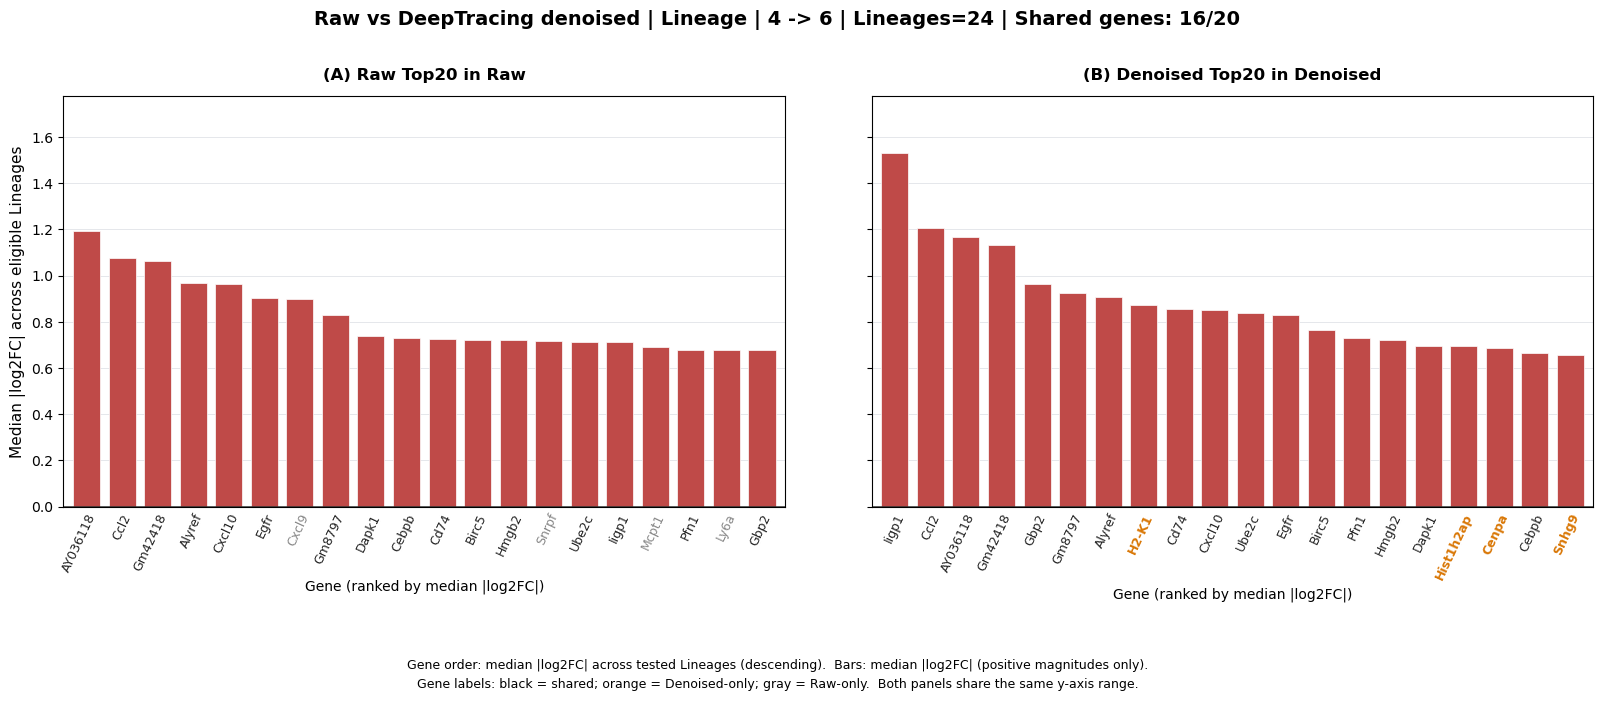

[SAVED] Lineage__4_to_6__raw_vs_denoised_top20__absolute_vertical_bars | groups=24 shared genes=4000 overlap=16/20
  groups: C1, C2, C3, C5, C10, C12, C13, C14, C23, C24, C26, C28, C30, C31, C36, C41, C45, C47, C56, C67, C68, C77, C85, C120
  shared: Alyref, AY036118, Birc5, Ccl2, Cd74, Cebpb, Cxcl10, Dapk1, Egfr, Gbp2, Gm8797, Gm42418, Hmgb2, Iigp1, Pfn1, Ube2c
  denoised-only: Cenpa, H2-K1, Hist1h2ap, Snhg9
  raw-only: Cxcl9, Ly6a, Mcpt1, Snrpf
Done: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results_gene_analyse/raw_vs_denoised_top20_bars
Gene analysis completed: /data/data2/wenyuhong/DeepTracing/experiments/eTracer/results_gene_analyse


{'raw': PosixPath('results_gene_analyse/raw_temporal_DE'),
 'denoised': PosixPath('results_gene_analyse/denoised_temporal_DE'),
 'heatmaps': PosixPath('results_gene_analyse/raw_vs_denoised_top20_median_abs_heatmap'),
 'bars': PosixPath('results_gene_analyse/raw_vs_denoised_top20_bars')}

In [15]:
from temporal_gene_analysis import run_temporal_gene_analysis

# Raw counts must remain unnormalized. Do not pass the normalized plotting adata.
gene_analysis_results = run_temporal_gene_analysis(
    raw_adata_file=data_dir / "eTracer_lineage_usable.h5ad",
    denoised_file=Path("./denoised_counts.txt"),
    output_dir="./results_gene_analyse",
    training_hvg_file=None,
    show=True,
)

gene_analysis_results